# 06 · Practical Guide

The decision guide, and working code to take with you.

| If you have... | Use | Why |
|---|---|---|
| Text / bag-of-words | **Multinomial NB** | Still an excellent, fast baseline |
| Continuous tabular features | **Gaussian NB** | A quick, honest first pass |
| A *tiny* training set | **Naive Bayes** | It will not overfit where complex models do |
| Any project, needing a baseline | **Naive Bayes** | The strong baseline a heavier model must beat |
| Binary presence/absence features | **Bernoulli NB** | Model form matches the feature type |

And the warning that outranks all of them: **trust its decisions, never its probabilities.**
If you need calibrated probabilities, recalibrate — shown at the end, connecting to the
calibration project.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

from src import artifacts
from src.config import SETTINGS
from src.datasets import synthetic, tabular
from src.evaluation.probability import calibration_data
from src.models import BernoulliNB, GaussianNB, MultinomialNB

np.set_printoptions(precision=4, suppress=True)

## 1. The whole family, working, in a few lines each

Each variant ships from scratch with smoothing. Match the model to the feature type.

In [2]:
summary = []

# Continuous features -> Gaussian
Xc, yc, _ = tabular.load_continuous()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.3, random_state=SETTINGS.seed)
acc_g = float((GaussianNB().fit(Xc_tr, yc_tr).predict(Xc_te) == yc_te).mean())
summary.append({"variant": "GaussianNB", "data": "continuous tabular", "accuracy": acc_g})

# Count features -> Multinomial
Xm, ym = synthetic.make_count_data(n_samples=4000, n_features=50, seed=4)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=SETTINGS.seed)
acc_m = float((MultinomialNB(alpha=1.0).fit(Xm_tr, ym_tr).predict(Xm_te) == ym_te).mean())
summary.append({"variant": "MultinomialNB", "data": "word/count features", "accuracy": acc_m})

# Binary presence/absence -> Bernoulli (binarise the same counts at >0)
acc_b = float((BernoulliNB(alpha=1.0, binarize=0.0).fit(Xm_tr, ym_tr).predict(Xm_te) == ym_te).mean())
summary.append({"variant": "BernoulliNB", "data": "binary presence/absence", "accuracy": acc_b})

for row in summary:
    print(f"  {row['variant']:<14} {row['data']:<26} accuracy={row['accuracy']:.3f}")

artifacts.save_json({"variants": summary}, "06_variant_summary")

  GaussianNB     continuous tabular         accuracy=0.942
  MultinomialNB  word/count features        accuracy=0.970
  BernoulliNB    binary presence/absence    accuracy=0.974


PosixPath('/workspaces/naive_bayes_101/outputs/data/06_variant_summary.json')

## 2. If you must have probabilities: recalibrate

Naive Bayes probabilities are overconfident (notebook 04). You do not have to live with that:
fit a monotonic **isotonic** map on a held-out slice, which keeps every decision identical
(it is monotonic) while repairing the numbers. Here, on deliberately correlated data, that
cuts the log loss dramatically.

In [3]:
X, y = synthetic.make_correlated_data(n_samples=6000, n_features=20, correlation=0.6,
                                      class_sep=1.0, seed=3)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, random_state=SETTINGS.seed)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=SETTINGS.seed)

nb = GaussianNB().fit(X_tr, y_tr)
p_val = nb.predict_proba(X_val)[:, 1]
p_te = nb.predict_proba(X_te)[:, 1]

iso = IsotonicRegression(out_of_bounds="clip").fit(p_val, y_val)
p_te_cal = iso.predict(p_te)

ll_raw = log_loss(y_te, np.clip(p_te, 1e-15, 1 - 1e-15), labels=[0, 1])
ll_cal = log_loss(y_te, np.clip(p_te_cal, 1e-15, 1 - 1e-15), labels=[0, 1])
acc_raw = float(((p_te >= 0.5).astype(int) == y_te).mean())
acc_cal = float(((p_te_cal >= 0.5).astype(int) == y_te).mean())
print(f"log loss  raw={ll_raw:.4f}  ->  recalibrated={ll_cal:.4f}")
print(f"accuracy  raw={acc_raw:.4f}      recalibrated={acc_cal:.4f}   (decisions unchanged)")

artifacts.save_json(
    {"log_loss_raw": ll_raw, "log_loss_recalibrated": ll_cal,
     "accuracy_raw": acc_raw, "accuracy_recalibrated": acc_cal},
    "06_recalibration",
)

log loss  raw=2.5544  ->  recalibrated=0.5262
accuracy  raw=0.7233      recalibrated=0.7233   (decisions unchanged)


PosixPath('/workspaces/naive_bayes_101/outputs/data/06_recalibration.json')

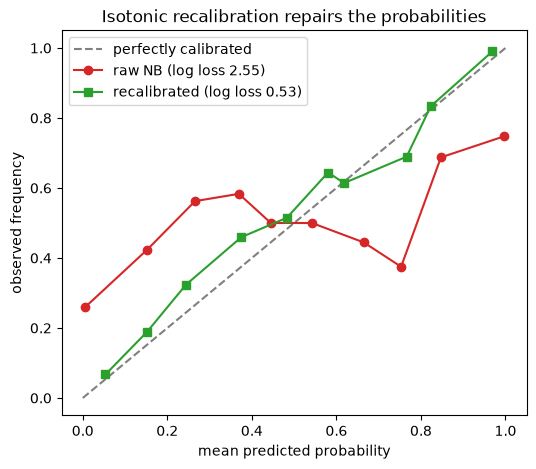

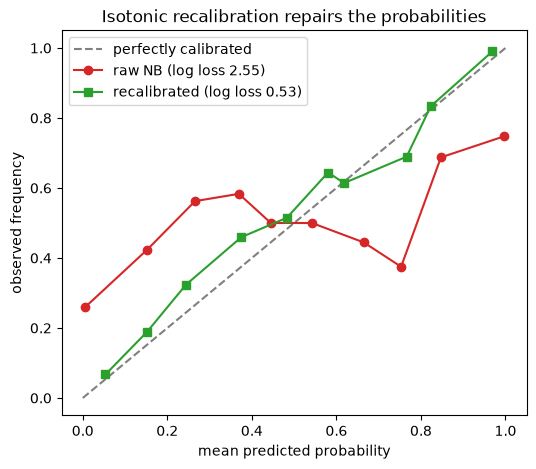

In [4]:
raw_x, raw_y = calibration_data(y_te, p_te, n_bins=10)
cal_x, cal_y = calibration_data(y_te, p_te_cal, n_bins=10)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfectly calibrated")
ax.plot(raw_x, raw_y, "o-", color="tab:red", label=f"raw NB (log loss {ll_raw:.2f})")
ax.plot(cal_x, cal_y, "s-", color="tab:green", label=f"recalibrated (log loss {ll_cal:.2f})")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed frequency")
ax.set_title("Isotonic recalibration repairs the probabilities")
ax.legend()
artifacts.save_fig(fig, "06_recalibration")
fig

## What you leave with

* Three from-scratch Naive Bayes variants (`GaussianNB`, `MultinomialNB`, `BernoulliNB`) with
  Laplace smoothing, matched to sklearn to 1e-9.
* A clear rule for when to reach for them — scarce data, sparse/high-dimensional text, and as
  the baseline every heavier model must beat.
* The one lesson the "wrong" model teaches better than any correct one: **a model can make
  the right decision for the wrong reasons.** Trust the decision; recalibrate if you need the
  probability.

Cross-links: Bayes' theorem comes from `bayesian_101`; the recalibration fix leads into
`calibration_arena`; the bag-of-words setting connects to `embeddings_101`.